In [3]:
import numpy as np
import matplotlib.pyplot as plt
from fraction import Fraction

In [4]:
def print_fraction(num):
    return str(Fraction(num))

# Simulatie van twee verschillende zuivere schatters (unbiased estimators) voor het gemiddelde $\mu$ van een normale verdeling:

1. Het steekproefgemiddelde $\bar{X}$
2. Een willekeurig gewogen gemiddelde $\frac{X_1 + 3X_2 + 2X_3}{6}$

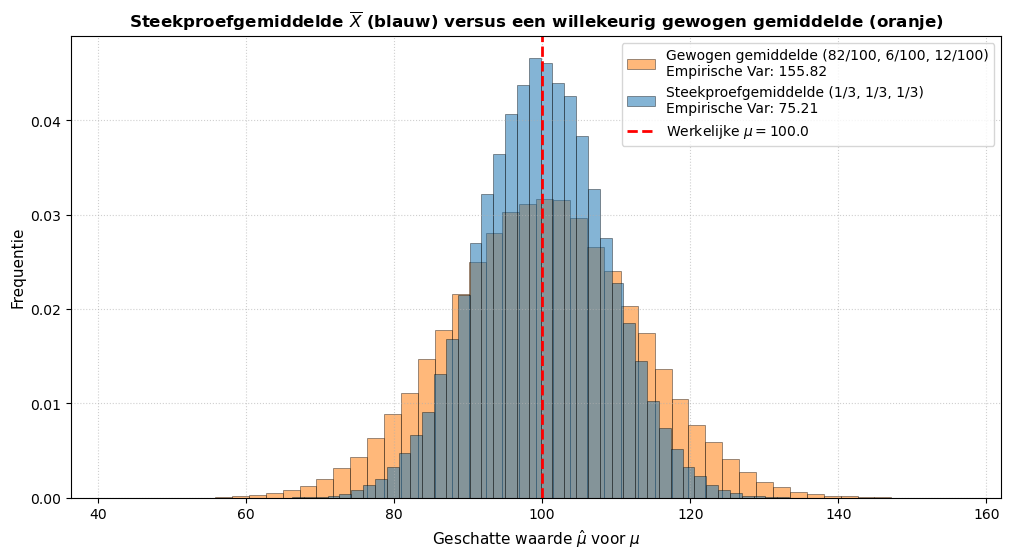

In [18]:
# Fixed seed voor reproduceerbaarheid in de collegezaal
np.random.seed(42)

# Algemene instellingen
N_SIM = 100_000
MU_TRUE = 100.0   # Werkelijke parameter die we schatten
SIGMA = 15.0      # Standaardafwijking

# ==============================================================================
# SITUATIE 1: GELIJKE VARIANTIES (Var(X1) = Var(X2) = Var(X3) = sigma^2)
# ==============================================================================

# Genereren van 100.000 steekproeven van grootte 3
num_vars = 3
samples = {}
for i in range(num_vars):
    samples[i] = np.random.normal(MU_TRUE, SIGMA, N_SIM)

# Schatter 1: Steekproefgemiddelde (1/3, 1/3, 1/3)
str_weights1 = [f"1/{num_vars}"] * num_vars
weights1 = list(eval(i) for i in str_weights1)
hat_mu_1_eq = np.array([ sum(weights1[i] * samples[i][j] for i in samples) for j in range(N_SIM)])

# Schatter 2: Gewogen gemiddelde (1/6, 1/2, 1/3)
str_weights2 = ["82/100", "6/100", "12/100"]
weights2 = [eval(i) for i in str_weights2]
assert sum(weights2) == 1 and len(samples) == len(weights2)
hat_mu_2_eq = np.array([ sum(weights2[i] * samples[i][j] for i in samples) for j in range(N_SIM)])

# ==============================================================================
# PLOTTEN VAN DE RESULTATEN
# ==============================================================================

fig, ax = plt.subplots(figsize=(12, 6))

# --- Subplot 1: Gelijke Varianties ---
ax.hist(hat_mu_2_eq, bins=50, density=True, alpha=0.55, color='#ff7f0e', 
         edgecolor='black', linewidth=0.5,
         label=f'Gewogen gemiddelde ({", ".join(str_weights2)})\nEmpirische Var: {np.var(hat_mu_2_eq):.2f}')

ax.hist(hat_mu_1_eq, bins=50, density=True, alpha=0.55, color='#1f77b4', 
         edgecolor='black', linewidth=0.5,
         label=f'Steekproefgemiddelde ({", ".join(str_weights1)})\nEmpirische Var: {np.var(hat_mu_1_eq):.2f}')


ax.axvline(MU_TRUE, color='red', linestyle='--', linewidth=2, label=f'Werkelijke $\\mu = {MU_TRUE}$')
ax.set_title("Steekproefgemiddelde $\\overline{X}$ (blauw) versus een willekeurig gewogen gemiddelde (oranje)", fontsize=12, fontweight='bold')
ax.set_xlabel('Geschatte waarde $\\hat{\\mu}$ voor $\\mu$', fontsize=11)
ax.set_ylabel('Frequentie', fontsize=11)
ax.legend(loc='upper right', frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)

# plt.suptitle(f'Simulatie van 100.000 steekproeven van grootte $n = {num_vars}$: vergelijking van zuivere schatter voor $\\mu$', fontsize=15, fontweight='bold', y=1.02)
# fig.tight_layout()
plt.savefig("./unbiased_estimators.png")